# EduPredict AI

Predicting a student's final marks from background, lifestyle, attendance, coursework and test scores with a small
neural network written from scratch in NumPy: one hidden layer of 16 ReLU neurons, mean-squared-error loss,
backpropagation and gradient descent. This notebook goes through the data, the split, the network's calculations,
training and evaluation.

> **The data is synthetic** (generated by `src/synthetic_data.py`; see `docs/synthetic_dataset.md`). It contains
> relationships chosen by the generator, not real student records, so the accuracy below shows that the method works,
> not how real students behave.

**Contents:** 1 Data · 2 Explore · 3 Split · 4 The network, step by step · 5 Is backpropagation correct? ·
6 Training curves · 7 Test results · 8 One student, all subjects · 9 Limitations

In [1]:
import json
import sys
from pathlib import Path

# Find the project root whether the notebook is opened from notebooks/ or from the repo root.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "ann.py").exists())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import preprocessing as pp
from src.ann import MLP, gradient_check
from src.evaluation import summarize

pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE = "#0071e3"
VARIANTS = ["early", "during_term", "late"]
print("Project root folder:", ROOT.name)

Project root folder: EduPredict AI


## 1. Data
One row is one **student-subject** pair. Each student takes 6 of the 8 subjects.

In [2]:
df = pp.load_raw(ROOT / pp.DATA_PATH)
print(f"{len(df):,} rows | {df.student_id.nunique():,} students | {df.subject.nunique()} subjects | {df.shape[1]} columns")
print("rows per student:", df.groupby("student_id").size().value_counts().to_dict())
print("missing values:", int(df.isna().sum().sum()))
df.head()

12,000 rows | 2,000 students | 8 subjects | 32 columns
rows per student: {6: 2000}
missing values: 0


,student_id,subject,gender,age,grade_level,subject_interest,class_size,prev_year_score,study_hours_week,attendance_pct,assignment_completion_pct,late_submissions,assignment_avg_score,class_participation,quiz_avg_score,midterm_score,final_exam_score,final_marks,parent_education,family_income_band,internet_access,commute_minutes,part_time_job,extracurricular_hours,sleep_hours,stress_level,health_status,tutoring,past_failures,grade_letter,passed,data_source
0,S0000,Mathematics,F,14,9,2,29,54.9,0.6,82.3,80.1,1,46.9,2,39.6,57.2,29.0,38.2,4,5,1,28,0,4.9,5.7,3,4,1,2,F,0,synthetic
1,S0000,English,F,14,9,4,20,72.3,1.2,89.7,77.5,2,50.7,3,60.5,60.4,46.8,50.3,4,5,1,28,0,4.9,5.7,3,4,1,2,D,1,synthetic
2,S0000,Physics,F,14,9,4,38,66.1,0.8,85.6,70.3,5,53.7,5,66.8,61.4,42.9,48.7,4,5,1,28,0,4.9,5.7,3,4,1,2,D,1,synthetic
3,S0000,Computer Science,F,14,9,2,33,60.4,2.0,87.4,82.9,1,46.4,1,54.8,50.2,43.1,45.2,4,5,1,28,0,4.9,5.7,3,4,1,2,D,1,synthetic
4,S0000,Economics,F,14,9,3,35,70.2,1.1,89.6,85.8,3,58.4,3,64.8,52.6,41.2,46.9,4,5,1,28,0,4.9,5.7,3,4,1,2,D,1,synthetic


**Target:** `final_marks` (0-100). **Never used as inputs:** `final_exam_score`, `grade_letter`, `passed` (they contain or
come from the target). The three models differ only in *when* their inputs are known:

| Model | Inputs known at | Adds |
|---|---|---|
| `early` | start of term | home, lifestyle, subject, last year's score |
| `during_term` | during term | + attendance, study hours, assignments, quizzes, participation |
| `late` | after the mid-term | + mid-term and assignment average (parts of the final mark) |

## 2. Explore

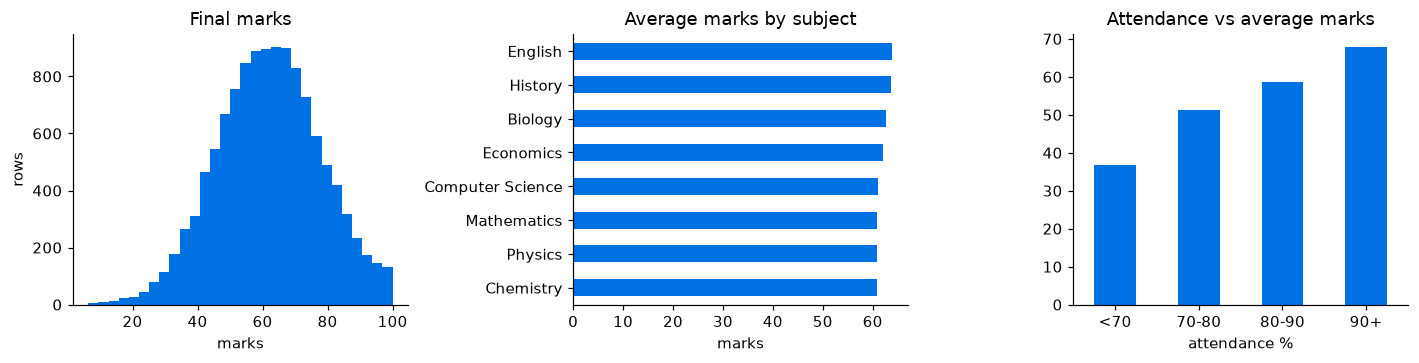

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
df.final_marks.plot.hist(bins=30, ax=ax[0], color=BLUE)
ax[0].set(title="Final marks", xlabel="marks", ylabel="rows")
df.groupby("subject").final_marks.mean().sort_values().plot.barh(ax=ax[1], color=BLUE)
ax[1].set(title="Average marks by subject", xlabel="marks", ylabel="")
att = pd.cut(df.attendance_pct, [0, 70, 80, 90, 101], labels=["<70", "70-80", "80-90", "90+"])
df.groupby(att, observed=True).final_marks.mean().plot.bar(ax=ax[2], color=BLUE, rot=0)
ax[2].set(title="Attendance vs average marks", xlabel="attendance %", ylabel="")
plt.tight_layout()

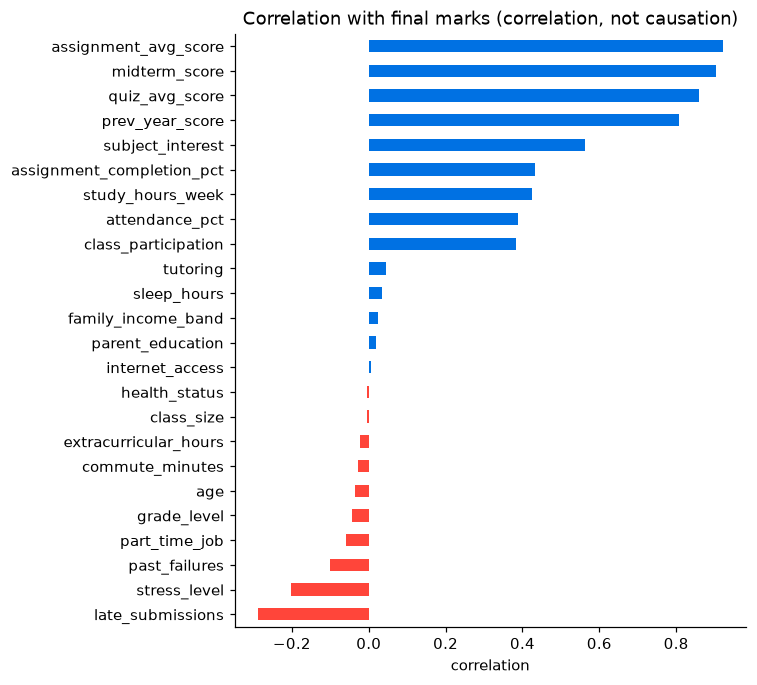

In [4]:
corr = df.select_dtypes("number").corr()["final_marks"].drop(["final_marks", "final_exam_score", "passed"]).sort_values()
corr.plot.barh(figsize=(6, 7), color=np.where(corr > 0, BLUE, "#ff453a"))
plt.title("Correlation with final marks (correlation, not causation)")
plt.xlabel("correlation");

## 3. Split
70/15/15 **by student**, so the same student never appears in two splits.

In [5]:
tr, va, te = pp.group_split(df, seed=42)
students = [set(df.iloc[i].student_id) for i in (tr, va, te)]
for name, idx, s in zip(("train", "val", "test"), (tr, va, te), students):
    print(f"{name:5s}: {len(idx):>5,} rows, {len(s):>4} students")
assert not (students[0] & students[1] or students[0] & students[2] or students[1] & students[2])
print("No student appears in more than one split.")

train: 8,400 rows, 1400 students
val  : 1,800 rows,  300 students
test : 1,800 rows,  300 students
No student appears in more than one split.


## 4. The network, step by step
Load the saved models, then follow one test row through `during_term` by hand.

In [6]:
models = {v: (MLP.load(ROOT / "models" / v / "weights.npz"), pp.load_config(ROOT / "models" / v / "preprocessing.json"))
          for v in VARIANTS}
for v, (net, cfg) in models.items():
    print(f"{v:12s}: {len(pp.column_names(cfg))} inputs -> {net.params['W1'].shape[1]} hidden (ReLU) -> 1 output (linear)")

early       : 25 inputs -> 16 hidden (ReLU) -> 1 output (linear)
during_term : 31 inputs -> 16 hidden (ReLU) -> 1 output (linear)
late        : 33 inputs -> 16 hidden (ReLU) -> 1 output (linear)


In [7]:
net, cfg = models["during_term"]
row = df.iloc[te].iloc[[0]]
x = pp.transform(row, cfg)                    # scaled with TRAIN statistics only
y_hat, (_, z1, a1) = net.forward(x)           # z1 = x.W1 + b1 ; a1 = ReLU(z1) ; y_hat = a1.W2 + b2

print(row[["student_id", "subject", "prev_year_score", "attendance_pct", "study_hours_week", "quiz_avg_score"]].to_string(index=False))
hidden = pd.DataFrame({"z1 (before ReLU)": z1.ravel(), "a1 = max(0, z1)": a1.ravel(),
                       "W2": net.params["W2"].ravel(), "a1 x W2": a1.ravel() * net.params["W2"].ravel()}).round(3)
hidden.index.name = "hidden neuron"
hidden

student_id     subject  prev_year_score  attendance_pct  study_hours_week  quiz_avg_score
     S0023 Mathematics             62.1            85.6               2.3            66.8


,z1 (before ReLU),"a1 = max(0, z1)",W2,a1 x W2
hidden neuron,,,,
0,-0.183,0.000,-0.349,-0.000
1,-0.107,0.000,0.144,0.000
2,0.138,0.138,-0.105,-0.014
3,1.325,1.325,-0.085,-0.113
4,0.126,0.126,0.296,0.037
5,0.251,0.251,-0.090,-0.023
6,-0.882,0.000,-0.010,-0.000
7,0.931,0.931,-0.040,-0.037
8,-0.805,0.000,-0.057,-0.000


In [8]:
total = float((a1 @ net.params["W2"])[0, 0])
b2 = float(net.params["b2"][0, 0])
print(f"sum(a1 x W2) = {total:.3f}   bias b2 = {b2:.3f}   ->  standardised output = {float(y_hat[0, 0]):.3f}")
pred = float(pp.unscale_target(y_hat, cfg)[0, 0])
print(f"x {cfg['target_std']:.2f} + {cfg['target_mean']:.2f}  ->  predicted {pred:.1f} marks   (actual: {row.final_marks.iloc[0]:.1f})")

sum(a1 x W2) = -0.350   bias b2 = 0.014   ->  standardised output = -0.337
x 15.66 + 61.92  ->  predicted 56.6 marks   (actual: 54.2)


## 5. Is backpropagation correct?
Compare the analytic gradients from backprop with numerical (finite-difference) gradients.

In [9]:
net, cfg = models["early"]
small = df.iloc[tr].head(20)
err = gradient_check(net, pp.transform(small, cfg), pp.scale_target(small[pp.TARGET], cfg))
print(f"max relative error between backprop and numerical gradients: {err:.2e}")
assert err < 1e-5

max relative error between backprop and numerical gradients: 1.49e-07


## 6. Training curves
From `results/training_history.csv`. Training stops early when validation loss stops improving.

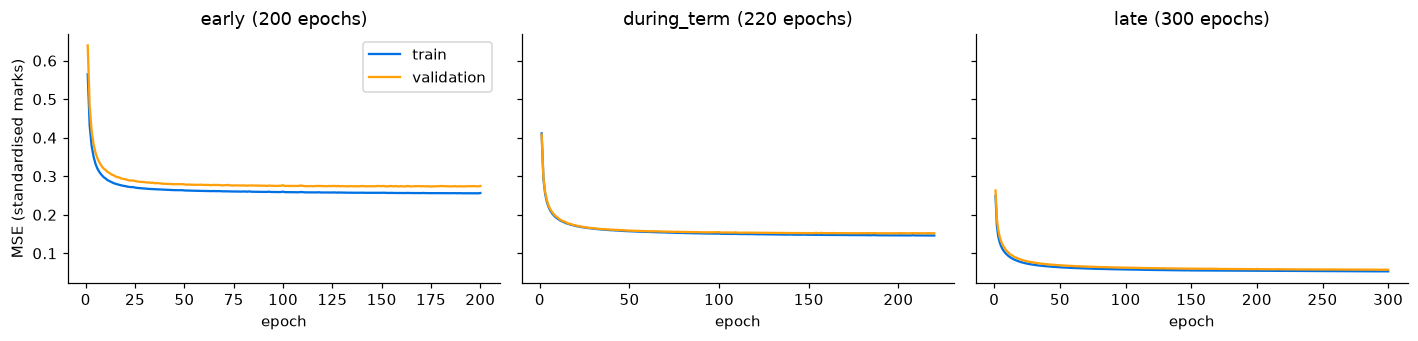

In [10]:
hist = pd.read_csv(ROOT / "results" / "training_history.csv")
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
for a, v in zip(ax, VARIANTS):
    h = hist[hist.variant == v]
    a.plot(h.epoch, h.train_loss, label="train", color=BLUE)
    a.plot(h.epoch, h.val_loss, label="validation", color="#ff9f0a")
    a.set(title=f"{v} ({len(h)} epochs)", xlabel="epoch")
ax[0].set_ylabel("MSE (standardised marks)")
ax[0].legend()
plt.tight_layout()

## 7. Test results
The 1,800 test rows (300 students the model has never seen) were used once, at the end.

In [11]:
metrics = json.loads((ROOT / "results" / "metrics.json").read_text())
table = pd.DataFrame([{"model": "baseline: predict the training mean", **metrics["early"]["test"]["baseline_mean"]}] +
                     [{"model": v, **metrics[v]["test"]["ann"]} for v in VARIANTS]).set_index("model")
table.round(2)

,mae,rmse,r2
model,,,
baseline: predict the training mean,13.13,16.52,-0.00
early,6.64,8.36,0.74
during_term,4.99,6.26,0.86
late,3.01,3.77,0.95


In [12]:
# Rebuild the test predictions from the saved models and confirm they equal the stored results.
preds = pd.read_csv(ROOT / "results" / "predictions.csv")
test = df.iloc[te]
for v in VARIANTS:
    net, cfg = models[v]
    again = pp.unscale_target(net.predict(pp.transform(test, cfg)), cfg)
    assert np.allclose(again, preds[f"pred_{v}"]), v
    assert abs(summarize(preds.actual, preds[f"pred_{v}"])["rmse"] - metrics[v]["test"]["ann"]["rmse"]) < 1e-6
print("Recomputed predictions and metrics match results/predictions.csv and results/metrics.json.")

Recomputed predictions and metrics match results/predictions.csv and results/metrics.json.


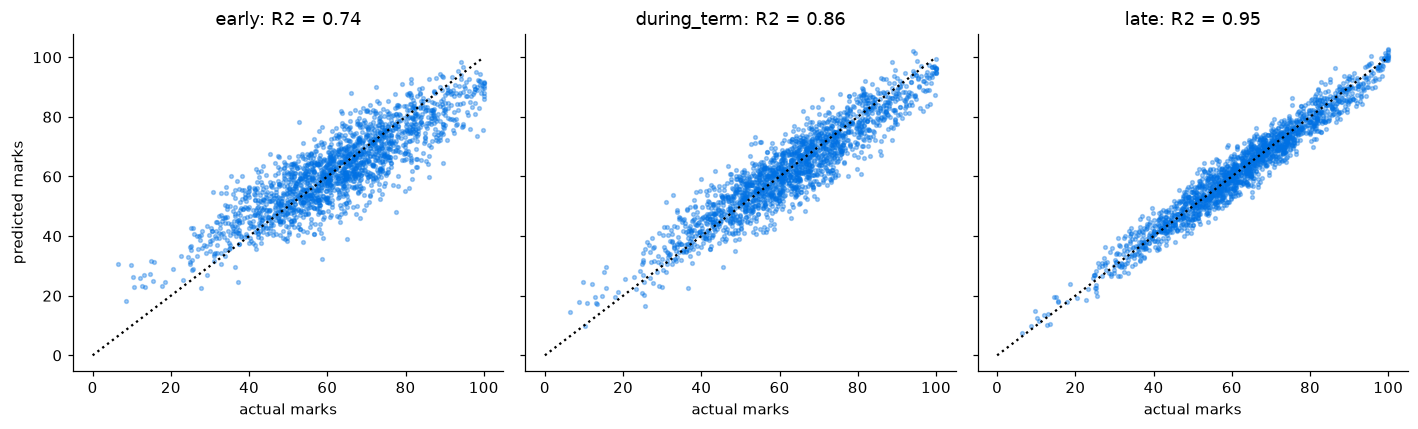

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(13, 4), sharex=True, sharey=True)
for a, v in zip(ax, VARIANTS):
    a.scatter(preds.actual, preds[f"pred_{v}"], s=6, alpha=.35, color=BLUE)
    a.plot([0, 100], [0, 100], "k:")
    a.set(title=f"{v}: R2 = {metrics[v]['test']['ann']['r2']:.2f}", xlabel="actual marks")
ax[0].set_ylabel("predicted marks")
plt.tight_layout()

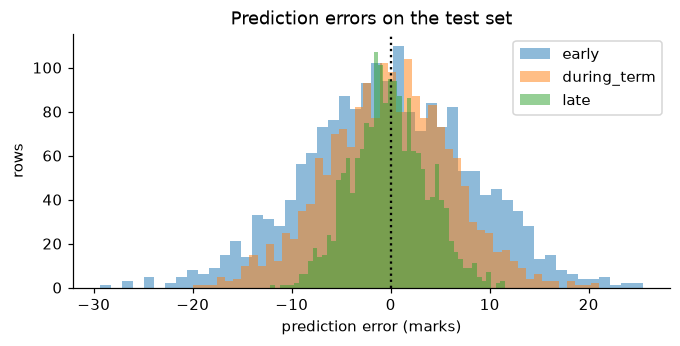

In [14]:
fig, ax = plt.subplots(figsize=(7, 3))
for v in VARIANTS:
    ax.hist(preds[f"pred_{v}"] - preds.actual, bins=50, alpha=.5, label=v)
ax.axvline(0, color="k", ls=":")
ax.set(xlabel="prediction error (marks)", ylabel="rows", title="Prediction errors on the test set")
ax.legend();

## 8. One student, all subjects
The model predicts one **student-subject** row at a time. Averaging a student's rows gives an overall estimate.

In [15]:
sid = preds.groupby("student_id").size().loc[lambda s: s == 6].index[0]
one = preds[preds.student_id == sid].set_index("subject")[["actual", "pred_early", "pred_during_term", "pred_late"]]
one.loc["AVERAGE"] = one.mean()
print("Student:", sid)
one.round(1)

Student: S0023


,actual,pred_early,pred_during_term,pred_late
subject,,,,
Mathematics,54.2,59.3,56.6,54.4
English,54.2,61.0,55.8,47.7
History,69.7,62.3,60.9,65.2
Biology,55.4,58.7,63.5,60.0
Economics,60.3,62.1,62.9,60.2
Computer Science,51.8,61.3,57.7,57.7
AVERAGE,57.6,60.8,59.6,57.5


In [16]:
by_student = preds.groupby("student_id")[["actual", "pred_early", "pred_during_term", "pred_late"]].mean()
print(f"Across {len(by_student)} unseen test students, error of the student's average marks:")
pd.DataFrame({v: summarize(by_student.actual, by_student[f"pred_{v}"]) for v in VARIANTS}).T.round(2)

Across 300 unseen test students, error of the student's average marks:


,mae,rmse,r2
early,4.21,5.16,0.88
during_term,2.25,2.78,0.96
late,1.30,1.56,0.99


## 9. Limitations

- **Synthetic data:** the network recovers what the generator contains; this says nothing about real students.
- **`late` partly reads the answer:** mid-term and assignment average are 40% of the final mark by construction.
- **Near-linear data:** validation error barely changes between 2 and 32 hidden neurons (`hidden_sweep_val_rmse` in
  `results/metrics.json`), so 16 hidden neurons are not shown to be necessary.
- **One split and one seed**, no confidence intervals.
- **Predictions are estimates from patterns, not guarantees,** and the what-if explorer is not causal.

To reproduce everything: `python -m src.synthetic_data`, then `python train.py`.